In [26]:
import numpy as np
import importlib
import path_planning

In [27]:
importlib.reload(path_planning)

<module 'path_planning' from '/Users/shash/Documents/Projects/SatelliteRendezvous/algorithm_testing/path_planning.py'>

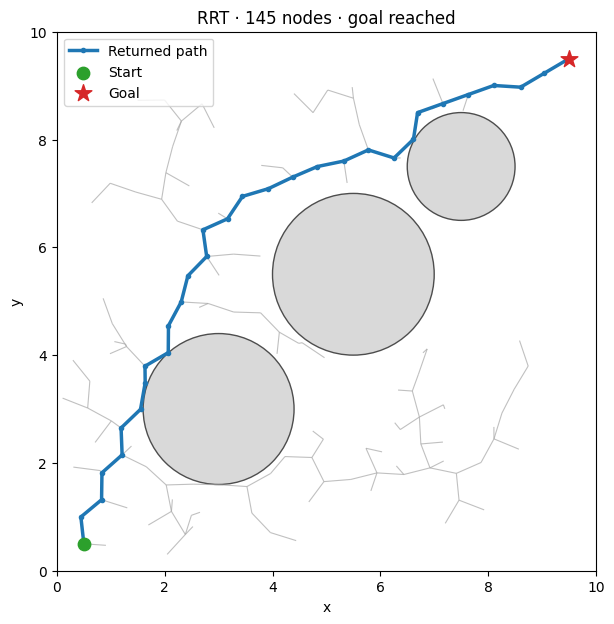

In [28]:
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Circle

start = (0.5, 0.5)
goal = (9.5, 9.5)
bounds = ((0, 10), (0, 10))
obstacles = [
    (3.0, 3.0, 1.4),
    (5.5, 5.5, 1.5),
    (7.5, 7.5, 1.0),
]

path, nodes = path_planning.plan_rrt(
    start, goal, bounds, obstacles,
    step_size=0.5,
    goal_tol=0.4,
    seed=42,
)

fig, ax = plt.subplots(figsize=(7, 7))

edges = [
    [node.parent.state, node.state]
    for node in nodes
    if node.parent is not None
]
ax.add_collection(
    LineCollection(edges, colors="0.65", linewidths=0.8, alpha=0.7)
)

for ox, oy, radius in obstacles:
    ax.add_patch(Circle((ox, oy), radius, facecolor="0.85", edgecolor="0.3"))

if path is not None:
    points = np.asarray(path)
    ax.plot(
        points[:, 0], points[:, 1],
        color="tab:blue", linewidth=2.5, marker=".", label="Returned path",
        zorder=3,
    )

ax.scatter(*start, color="tab:green", s=80, label="Start", zorder=4)
ax.scatter(*goal, color="tab:red", marker="*", s=160, label="Goal", zorder=4)
ax.set(
    xlim=bounds[0],
    ylim=bounds[1],
    xlabel="x",
    ylabel="y",
    title=f"RRT · {len(nodes)} nodes · {'goal reached' if path is not None else 'no path found'}",
)
ax.set_aspect("equal")
ax.legend()
plt.show()

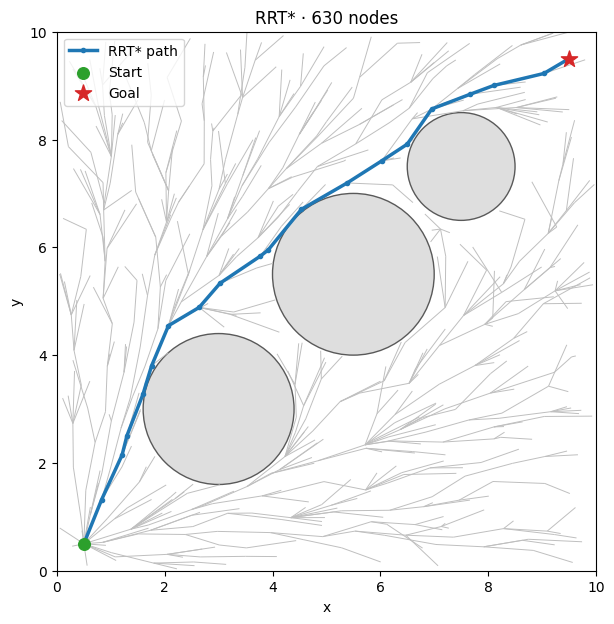

Passed · path length 13.491 · 20 path edges


In [29]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Circle

start = (0.5, 0.5)
goal = (9.5, 9.5)
bounds = ((0, 10), (0, 10))
obstacles = [(3.0, 3.0, 1.4), (5.5, 5.5, 1.5), (7.5, 7.5, 1.0)]

path, nodes = path_planning.plan_rrt_star(
    start, goal, bounds,
    radius=1.0,
    obstacles=obstacles,
    step_size=0.5,
    goal_tol=0.4,
    max_iter=800,
    seed=42,
)

fig, ax = plt.subplots(figsize=(7, 7))
edges = [
    [node.parent.state, node.state]
    for node in nodes
    if node.parent is not None
]
ax.add_collection(LineCollection(edges, colors="0.75", linewidths=0.7))

for ox, oy, radius in obstacles:
    ax.add_patch(Circle((ox, oy), radius, facecolor="0.87", edgecolor="0.35"))

if path is not None:
    xy = np.asarray(path)
    ax.plot(*xy.T, ".-", color="tab:blue", linewidth=2.5, label="RRT* path", zorder=3)

ax.scatter(*start, color="tab:green", s=70, label="Start", zorder=4)
ax.scatter(*goal, color="tab:red", marker="*", s=150, label="Goal", zorder=4)
ax.set(xlim=bounds[0], ylim=bounds[1], xlabel="x", ylabel="y",
       title=f"RRT* · {len(nodes)} nodes")
ax.set_aspect("equal")
ax.legend()
plt.show()

root = nodes[0]
assert root.parent is None and root.cost == 0.0

for node in nodes:
    for child in node.children:
        assert child.parent is node

    if node.parent is not None:
        assert node.parent.children.count(node) == 1
        expected_cost = node.parent.cost + path_planning.distance(node.parent.state, node.state)
        assert np.isclose(node.cost, expected_cost), f"Stale cost at {node.state}"

assert path is not None, "No goal connection found within the iteration budget"
np.testing.assert_allclose(path[0], start)
np.testing.assert_allclose(path[-1], goal)

for i, (a, b) in enumerate(zip(path, path[1:])):
    a, b = np.asarray(a), np.asarray(b)
    delta = b - a
    length_sq = delta @ delta

    for ox, oy, radius in obstacles:
        center = np.array([ox, oy])
        fraction = 0.0
        if length_sq > 0:
            fraction = np.clip((center - a) @ delta / length_sq, 0.0, 1.0)
        closest = a + fraction * delta
        assert path_planning.distance(closest, center) > radius, f"Path edge {i} touches a circle"

length = sum(path_planning.distance(a, b) for a, b in zip(path, path[1:]))
print(f"Passed · path length {length:.3f} · {len(path) - 1} path edges")